# FE V1_A12: Đặc trưng lịch tạo mốc sai số như thế nào?

Mục tiêu: đối chứng nhóm đặc trưng bằng một RF cố định.

Nhận xét phương án này nằm ở mục 5. Sau khi chạy V1–V5, mở `feature_comparison.ipynb` để so sánh chung và chọn cấu hình.

Các hàm xử lý nằm trong `src/feature_experiments.py`; notebook giữ các bước phân tích.

In [8]:
from pathlib import Path
import sys
project_root = next(folder for folder in (Path.cwd(), *Path.cwd().parents)
                    if (folder / 'data/Metro_Interstate_Traffic_Volume.csv').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
import pandas as pd
from IPython.display import Markdown, display
from src import feature_experiments as fe
CONFIG = 'V1_A12'

## 1. Câu hỏi và tập đặc trưng

Đặc trưng lịch tạo mốc sai số như thế nào?

`hour`; `day_of_week`; `month`; `is_weekend`; `is_rush_hour`; `hour_sin`; `hour_cos`; `day_of_week_sin`; `day_of_week_cos`; `month_sin`; `month_cos`; `is_holiday`.

V1 là mốc; V2/V3 cô lập hai nhóm weather; V4 kết hợp hai nhóm; V5 thêm history. Đây là đối chứng theo nhóm, chưa phải thử thêm từng cột.

## 2. Protocol dùng chung

Cả năm phương án dùng RandomForestRegressor với 400 cây, max_depth=12, min_samples_leaf=5, max_features=1.0 và random_state=42. Không tìm tham số ở giai đoạn này.

FE đọc `data/preprocessed/hourly_unfilled.csv` do notebook tiền xử lý xuất, với keep_default_na=False. Mỗi timestamp giữ một target; số đo thời tiết gộp median trên giá trị phân biệt, nhãn gộp thành tập hợp. Mask 0 K và điểm mưa nghi vấn theo quy tắc chung. Giờ thiếu không được điền target bằng 0. Nhãn lễ lấy theo ngày trong CSV; chưa bổ sung lịch ngoài.

Chỉ dùng 70% giờ quan sát đầu tiên làm train. Cả năm cùng lấy các giờ có đủ ba feature lịch sử, rồi dùng TimeSeriesSplit(n_splits=3). Vì thiếu giờ, các fold có thể khác thời lượng lịch dù số dòng chấm bằng nhau.

Trong từng fold, median nhiệt độ theo tháng/giờ và median mưa chỉ học từ fold-train. Nhiệt độ thiếu ưu tiên quan sát gốc trước đó tối đa 6 giờ rồi mới dùng median. Không lấy quan sát tương lai để điền. Danh sách 11 cờ weather cố định theo cấu hình, không học encoder trên fold-score. RF không cần scaler; mọi phương án dùng bảng số float32 giống nhau trước khi chọn cột.

Lag là giá trị ở một thời điểm quá khứ: lag_24h và lag_168h được tra đúng timestamp. mean_24h dùng [t−24h,t), ít nhất 18 quan sát và không dùng target tại t. Khi chấm tuần tự, target thực đã đến ở các giờ trước trong fold-score có thể làm lịch sử; đây chưa phải dự báo nhiều bước từ một mốc.

Weather cùng giờ được giả định sẵn có. Nếu cần dự báo trước giờ đó, phải thay bằng dự báo thời tiết và đánh giá lại. Timestamp chưa phân tích DST. Định nghĩa giờ cao điểm và nhóm feature đã được chọn ở bước thăm dò; CV ở đây phục vụ lựa chọn nội bộ, chưa phải điểm test cuối cùng.

In [9]:
context = fe.load_protocol(project_root)
cohort = context['cohort']
display(pd.DataFrame([dict(config=CONFIG, n_features=len(fe.CONFIGS[CONFIG]),
                           n_train=len(context['train']), n=len(cohort),
                           excluded_hours=len(context['train']) - len(cohort),
                           protocol_id=context['protocol_id'])]))

,config,n_features,n_train,n,excluded_hours,protocol_id
0,V1_A12,12,28402,22503,5899,e4bc1e064317af8c


## 3. Các fold theo thời gian

CV là đánh giá lặp lại theo nhiều lần chia train/score. Mỗi lần chỉ học từ quá khứ rồi chấm giai đoạn sau. Bảng ghi thời gian, số giờ chấm n và số giờ học n_fit để kiểm tra tính đồng nhất.

In [10]:
display(context['manifest'])

,fold,fit_start,fit_end,score_start,score_end,n_fit,n,fit_calendar_hours,score_calendar_hours,fit_hash,score_hash
0,1,2012-10-09 09:00:00,2013-08-05 19:00:00,2013-08-05 20:00:00,2015-07-12 06:00:00,5628,5625,7211.0,16931.0,907f339dcf7453df3f5e70f83fd477f72bdfd531e01eae...,3e445aa0bc2af81e32b3d2126a6f9e34073d17a6872bc0...
1,2,2012-10-09 09:00:00,2015-07-12 06:00:00,2015-07-12 07:00:00,2016-09-07 17:00:00,11253,5625,24142.0,10163.0,0a956b96e0a294dfd75ca7d8b49aa36b9e6cbffd755794...,a1d7f7f4f11fc1da3571b8dfdba463987d69e3ef1adee3...
2,3,2012-10-09 09:00:00,2016-09-07 17:00:00,2016-09-07 18:00:00,2017-05-10 04:00:00,16878,5625,34305.0,5867.0,a64f6fc3241daadbcf0a479c22878e11e10c69bfa3c4e2...,4117d3a132e44ecc9c0f8eea01e43dc911e7758ea92dc3...


## 4. Huấn luyện và đánh giá

MAE đo độ lệch tuyệt đối trung bình. RMSE nhạy hơn với sai số lớn. Cả hai có đơn vị xe/giờ, càng thấp càng tốt. Các ô sau thực sự huấn luyện lại ba fold, không đọc điểm của thí nghiệm cũ.

In [11]:
scores = fe.run_configuration(context, CONFIG)
display(scores[['config', 'fold', 'fit_start', 'fit_end', 'score_start', 'score_end',
                'n_fit', 'n', 'n_features', 'MAE', 'RMSE', 'R2']])

V1_A12, fold 1/3: MAE=250.918, RMSE=442.855
V1_A12, fold 2/3: MAE=321.433, RMSE=534.358
V1_A12, fold 3/3: MAE=292.603, RMSE=431.845


,config,fold,fit_start,fit_end,score_start,score_end,n_fit,n,n_features,MAE,RMSE,R2
0,V1_A12,1,2012-10-09 09:00:00,2013-08-05 19:00:00,2013-08-05 20:00:00,2015-07-12 06:00:00,5628,5625,12,250.918424,442.854560,0.950188
1,V1_A12,2,2012-10-09 09:00:00,2015-07-12 06:00:00,2015-07-12 07:00:00,2016-09-07 17:00:00,11253,5625,12,321.432576,534.357921,0.925300
2,V1_A12,3,2012-10-09 09:00:00,2016-09-07 17:00:00,2016-09-07 18:00:00,2017-05-10 04:00:00,16878,5625,12,292.603496,431.845127,0.951037


,config,MAE_mean,MAE_std,RMSE_mean,RMSE_std,n
0,V1_A12,288.318165,35.451861,469.685869,56.277505,16875


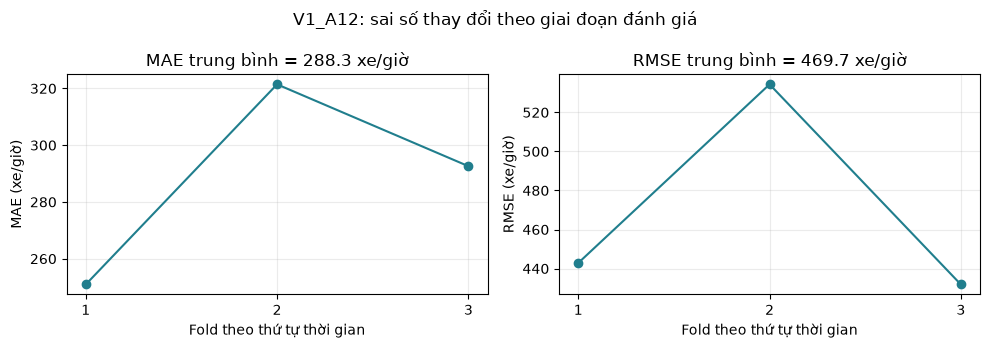

In [12]:
display(pd.DataFrame([dict(config=CONFIG, MAE_mean=scores.MAE.mean(),
                           MAE_std=scores.MAE.std(ddof=1), RMSE_mean=scores.RMSE.mean(),
                           RMSE_std=scores.RMSE.std(ddof=1), n=int(scores.n.sum()))]))
fe.plot_scores(context, scores)

Đọc biểu đồ này như sau: mỗi điểm là sai số trên một giai đoạn chấm. Sai số thay đổi cùng thời kỳ và lượng dữ liệu học; không diễn giải ba fold như ba mẫu độc lập.

## 5. Nhận xét A12

A12 là cấu hình mốc chỉ dùng lịch và cờ ngày lễ. MAE/RMSE ở mục 4 cho biết sai số khi chưa thêm weather hoặc history. Đọc cả ba fold để thấy sai số thay đổi theo giai đoạn.

Dùng kết quả này làm đối chứng cho các phương án bổ sung đặc trưng. Bảng so sánh cả năm và quyết định cuối nằm trong `feature_comparison.ipynb`.

Kết quả chỉ áp dụng cho RF, tham số và tập giờ đang dùng; chưa đánh giá validation/test hoặc đóng góp riêng của từng cột. Notebook này lưu kết quả của phương án hiện tại. Việc chọn cấu hình và xuất dữ liệu cho tuning thực hiện trong `feature_comparison.ipynb`.